# Separar un sesgo del transporte y de los sólidos acumulados

**Pregunta:** ¿Cómo distinguimos un sesgo grande de alimentación de cambios sanos de transporte e inventario
antes de interpretar un residuo de conciliación?

Nivel 2 · Requisito: lección 01 sobre conciliación de flotación. · Lectura: 40 minutos.

## Objetivos

Un optimizador puede cerrar perfectamente una ecuación equivocada. Crearemos primero una transición sana
de carga sin ruido instrumental y llevaremos cada canal a una misma parcela. Luego ejecutaremos el modelo
de espesador para exponer el cambio de inventario que efectivamente calcula su esquema de volúmenes finitos.
Después de esas verificaciones compararemos correcciones cuadráticas y de Huber ante un sesgo inyectado.
Aprenderemos un orden de diagnóstico: revisar el soporte temporal y el almacenamiento antes de evaluar
la respuesta del estimador.

## Preparación

Trabaja en una copia de OreBridge con el entorno de notebooks activo. Los métodos computacionales están en
`data-pipeline/pipeline`; se necesita el repositorio y no se presupone una distribución OreBridge en PyPI.
Instala estas dependencias numéricas exactas una vez, fuera de este notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Inicia el kernel con `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` y `MKL_NUM_THREADS=1`.
La preparación encuentra el repositorio desde el directorio de trabajo sin imprimir una ruta de la máquina.

In [1]:
# Usar el entorno de CPU con versiones fijas e importar los métodos científicos implementados.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import generate, align, conservation_matrix, channel_specs
from pipeline.model.reconciliation import weighted_reconcile, robust_reconcile
from pipeline.model.thickener import simulate_thickener
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Datos

Responsable: OreBridge, [repositorio](https://github.com/fsantibanezleal/CAOS_OreBridge), MIT; categoría
sintética de autoría del proyecto. `data-pipeline/pipeline/model/scenarios.py` define los dieciséis canales
y el generador de transporte con semilla. `data-pipeline/pipeline/model/thickener.py` contiene el modelo
de referencia de volúmenes finitos. La reproducción `data/derived/PL-01/trace.json` documenta el mismo contrato
de canales. Generaremos localmente la semilla 1000; la verdad latente se reserva para validar el experimento,
sin entregarla al estimador.

## Método

Un balance compara magnitudes con el mismo soporte material y temporal. En el generador, la carga de origen
llega al canal $j$ tras $d_j$ segundos. Sea $D=14$ segundos el mayor retardo declarado. El paquete forma
$z_j(t)=y_j(t-(D-d_j))$: usa observaciones actuales o anteriores y deja las primeras $D$ filas sin información
disponible. Es un supuesto de transporte de autoría del proyecto, no una distribución de residencia
estimada. Se puede verificar conservación para la parcela alineada, pero eso no demuestra que los retardos
representen una planta real. La referencia mineralúrgica motiva el balance; el código de OreBridge especifica
este operador temporal concreto ([referencia de conciliación](https://doi.org/10.1016/j.mineng.2018.04.023)).

Fijamos primero el ruido en cero. Si el balance instantáneo falla, no podemos atribuirlo al error aleatorio
de medición. Conservamos los once factores: los primeros nueve corresponden a sólidos y los dos últimos
a agua. Normalizamos cada factor mediante su propia incertidumbre propagada antes de compararlos; no
sumamos toneladas por hora con metros cúbicos por hora.

In [2]:
# Eliminar el ruido para aislar la discrepancia causada por tiempos materiales distintos.
healthy = generate("healthy", seed=1000, noise=0)
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
factor_sigma = np.sqrt((matrix * matrix) @ (sigma * sigma))
raw_residual = healthy.observed[14:] @ matrix.T
print(f"Mayor residuo simultáneo de sólidos secos: {np.max(np.abs(raw_residual[:, :9])):.6f} t/h")

Mayor residuo simultáneo de sólidos secos: 263.223537 t/h


Alineamos las mismas observaciones mediante el operador causal implementado. No suavizamos datos ni usamos
verdad limpia para estimar estados. La comparación pregunta si el transporte por sí solo explica la
discrepancia en este modelo sintético deliberadamente exacto. El máximo normalizado entre factores facilita
la figura; el residuo impreso de sólidos conserva una unidad de ingeniería reconocible.

Mayor residuo alineado de sólidos secos: 0.000000000000 t/h


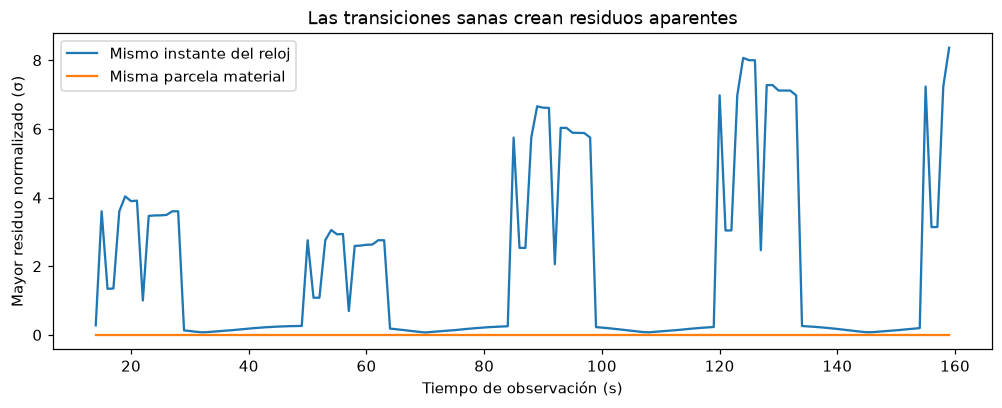

In [3]:
# Comparar el cierre del reloj con el cierre de una misma parcela.
aligned_healthy = align(healthy.observed)
aligned_residual = aligned_healthy[14:] @ matrix.T
print(f"Mayor residuo alineado de sólidos secos: {np.max(np.abs(aligned_residual[:, :9])):.12f} t/h")
time_s = np.arange(14, len(healthy.observed))
raw_max = np.max(np.abs(raw_residual) / factor_sigma, axis=1)
aligned_max = np.max(np.abs(aligned_residual) / factor_sigma, axis=1)
fig, axis = plt.subplots(figsize=(9, 3.6), layout="constrained")
axis.plot(time_s, raw_max, label="Mismo instante del reloj")
axis.plot(time_s, aligned_max, label="Misma parcela material")
axis.set(title="Las transiciones sanas crean residuos aparentes", xlabel="Tiempo de observación (s)",
         ylabel="Mayor residuo normalizado (σ)")
axis.legend()
plt.show()

Los picos pertenecen a un proceso sano y sin ruido: los canales aguas arriba y abajo muestrean porciones
distintas de un cambio de carga. La alineación lleva los factores a cero numérico porque el experimento
se generó con exactamente esos retardos. Verifica la implementación, pero no demuestra que catorce segundos
sea un retardo universal. Con mezcla desconocida, recirculación o metadatos temporales incorrectos hay que
estimar el soporte temporal o rechazar el factor estacionario.

El transporte no es la única causa. Un espesador almacena sólidos, de modo que su balance integrado es
$V_{s,\mathrm{in}}-V_{s,\mathrm{out}}=M_f-M_i$; aquí todos los términos son volúmenes de sólidos en m³.
El modelo fuente evoluciona una fracción vertical de sólidos con un esquema conservativo de volúmenes
finitos y sedimentación impedida. Usamos 640 celdas verticales. La geometría fija y las dos horas son entradas didácticas.
Se excluyen compresión, cinética de floculación y flujo radial. Lo ejecutamos para obtener el inventario.

In [4]:
# Ejecutar el modelo de volúmenes finitos y conservar el balance integrado de sólidos.
thickener = simulate_thickener(cells=640)
inventory_change = thickener["final_solids_m3"] - thickener["initial_solids_m3"]
volumes = np.array([thickener["feed_solids_m3"], thickener["outlet_solids_m3"]])
print(f"Cambio de sólidos almacenados: {inventory_change:.6f} m³")
print(f"Sólidos de entrada: {volumes[0]:.6f} m³; Sólidos de salida: {volumes[1]:.6f} m³")
print(f"Residuo de cierre con almacenamiento: {thickener['solids_residual_m3']:.12f} m³")

Cambio de sólidos almacenados: -0.290800 m³
Sólidos de entrada: 3.200000 m³; Sólidos de salida: 3.490800 m³
Residuo de cierre con almacenamiento: 0.000000000000 m³


Tratamos los dos volúmenes integrados como un problema pequeño de conciliación. Asignamos incertidumbre
estándar de 0.05 m³ a cada uno solo para esta sensibilidad; el modelo de espesador no estima incertidumbre
instrumental. Primero imponemos almacenamiento cero y luego entregamos el cambio de inventario calculado
como término independiente. El mismo optimizador resolverá ambos problemas: su éxito no decide si la ecuación
física era adecuada. En un recipiente instrumentado, el inventario necesita medición e incertidumbre propias.

In [5]:
# Hacer explícito el supuesto de inventario en el término independiente de la igualdad.
volume_constraint = np.array([[1.0, -1.0]])
volume_sigma = np.array([0.05, 0.05])
naive_storage = weighted_reconcile(volumes, volume_sigma, volume_constraint, [0.0])
dynamic_storage = weighted_reconcile(volumes, volume_sigma, volume_constraint, [inventory_change])
naive_move = np.max(np.abs(naive_storage["state"] - volumes))
dynamic_move = np.max(np.abs(dynamic_storage["state"] - volumes))
print(f"Mayor movimiento al ignorar almacenamiento: {naive_move:.6f} m³; "
      f"al incluir almacenamiento: {dynamic_move:.12f} m³")

Mayor movimiento al ignorar almacenamiento: 0.145400 m³; al incluir almacenamiento: 0.000000000000 m³


Mostramos la trayectoria del inventario simulado y los dos pares conciliados de volúmenes. Vinculamos así
el estado temporal con el balance integrado, sin interpretar entrada menos salida positiva como pérdida.
Los totales cubren las dos horas completas aunque la trayectoria se muestrea con menor frecuencia para
graficar; provienen directamente de la contabilidad conservativa del modelo.

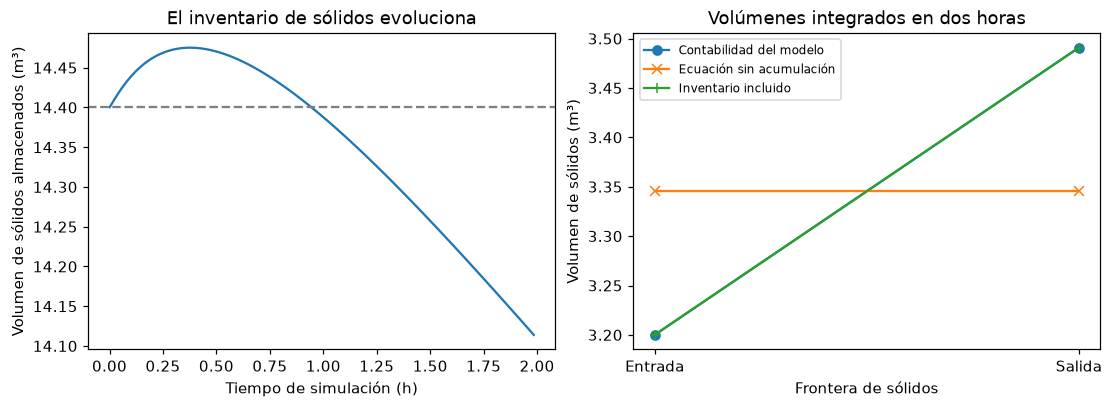

In [6]:
# Contrastar la acumulación modelada con los ajustes artificiales del supuesto estacionario.
timeline = np.array(thickener["timeline"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(timeline[:, 0], timeline[:, 3])
axes[0].axhline(thickener["initial_solids_m3"], color="grey", linestyle="--")
axes[0].set(title="El inventario de sólidos evoluciona", xlabel="Tiempo de simulación (h)",
            ylabel="Volumen de sólidos almacenados (m³)")
series = [(volumes, "o", "Contabilidad del modelo"),
          (naive_storage["state"], "x", "Ecuación sin acumulación"),
          (dynamic_storage["state"], "+", "Inventario incluido")]
for values, marker, name in series:
    axes[1].plot([0, 1], values, marker=marker, label=name)
axes[1].set_xticks([0, 1], ["Entrada", "Salida"])
axes[1].set(title="Volúmenes integrados en dos horas", xlabel="Frontera de sólidos", ylabel="Volumen de sólidos (m³)")
axes[1].legend(fontsize=8)
plt.show()

Tras un aumento inicial, el inventario final queda por debajo del inicial y el volumen de salida supera
el de entrada. La ecuación dinámica conserva esos totales modelados. La ecuación sin acumulación
arrastra ambos hacia un valor común y fabricaría dos correcciones instrumentales. La trayectoria no valida
un espesador industrial: expone el término omitido de cambio de inventario. Alinear las marcas temporales no
elimina ese término: el recipiente primero acumula sólidos y al final contiene menos que al inicio.

Ahora investigamos un sesgo numérico inyectado manteniendo fijo el soporte temporal. Con severidad cuatro,
el generador agrega dieciséis incertidumbres estándar a la alimentación de flotación durante el intervalo
afectado. La conciliación de Huber minimiza $\sum_j\rho_{1.5}((x_j-y_j)/\sigma_j)$ con las mismas ecuaciones,
donde $\rho_\delta(r)=r^2/2$ si $|r|\leq\delta$ y $\delta(|r|-\delta/2)$ en el resto
([Huber, 1964](https://doi.org/10.1214/aoms/1177703732)). Sus pesos iterativos reducen la influencia de residuos
grandes; no prueban que el canal de alimentación los causó. El paquete realiza esas iteraciones.

In [7]:
# Comparar estimadores sobre la misma fila sesgada y alineada; reservar la verdad para evaluar.
biased = generate("bias", seed=1000, severity=4)
biased_row = align(biased.observed)[90]
validation_truth = align(biased.truth)[90]
quadratic = weighted_reconcile(biased_row, sigma, matrix, np.zeros(11))
robust = robust_reconcile(biased_row, sigma, matrix, np.zeros(11))
errors = np.column_stack([np.abs(quadratic["state"] - validation_truth) / sigma,
                          np.abs(robust["state"] - validation_truth) / sigma])
print(f"Error absoluto medio del estado, WLS: {errors[:, 0].mean():.6f} σ")
print(f"Error absoluto medio del estado, Huber: {errors[:, 1].mean():.6f} σ; iteraciones: {robust['iterations']}")
print(f"Objetivo de Huber: {robust['objective']:.6f}")

Error absoluto medio del estado, WLS: 1.105407 σ
Error absoluto medio del estado, Huber: 0.304784 σ; iteraciones: 20
Objetivo de Huber: 31.753924


Usamos la verdad sintética conocida para examinar dónde se desplazó cada estimación. Un error medio podría
ocultar la propagación del sesgo de alimentación hacia caudales vecinos. Mostrar todos los canales permite
ver esa redistribución. La incertidumbre instrumental es aquí la unidad de normalización; comparamos error
de estado, algo distinto de una puntuación residual para alarmas y de identificar causalmente una falla.

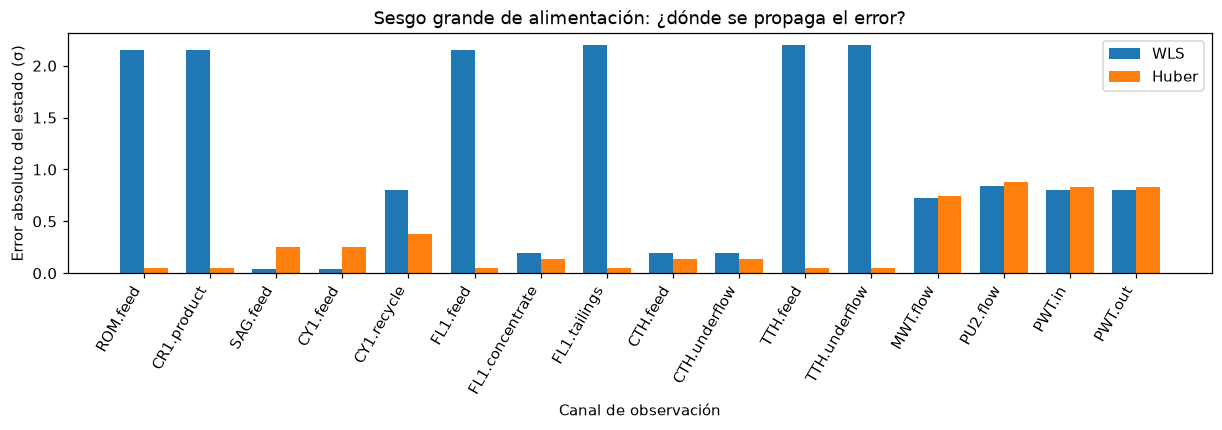

In [8]:
# Mostrar la distribución del error de estado y no solamente un promedio agregado.
positions = np.arange(16)
fig, axis = plt.subplots(figsize=(11, 3.8), layout="constrained")
axis.bar(positions - 0.18, errors[:, 0], 0.36, label="WLS")
axis.bar(positions + 0.18, errors[:, 1], 0.36, label="Huber")
axis.set_xticks(positions, [s["id"] for s in specs], rotation=60, ha="right")
axis.set(title="Sesgo grande de alimentación: ¿dónde se propaga el error?", xlabel="Canal de observación",
         ylabel="Error absoluto del estado (σ)")
axis.legend()
plt.show()

En esta fila la estimación de Huber contiene mejor el daño del sesgo grande que la proyección cuadrática.
Queda error y la ventaja depende de esta falla, el patrón de incertidumbres y la escala de pérdida elegida.
No puede extenderse a cambios balanceados, observaciones faltantes o topología equivocada. La siguiente
lección prueba precisamente un cambio balanceado: cerrar conservación ayuda poco y la predicción temporal
aprendida responde una pregunta diferente.

## Resultados

**Respuesta:** Una transición sana sin ruido produce un residuo simultáneo de sólidos de 263.223537 t/h,
que baja a 0.000000000000 t/h con la precisión mostrada después de alinear parcelas. El espesador libera
0.290800 m³ de inventario inicial; ignorarlo fuerza un movimiento innecesario de 0.145400 m³ en cada volumen.
En la fila sesgada alineada, el error medio normalizado del estado es 1.105407 σ con WLS y 0.304784 σ con
Huber, tras 20 iteraciones. Son tres explicaciones distintas, no tres niveles intercambiables de alarma.

El orden correcto comienza con la física: rechazar un balance instantáneo sin soporte, incorporar el
inventario variable y después interpretar cómo el estimador distribuye una discrepancia admitida. Los
metadatos de calidad también son un requisito. Los valores finitos aceptados de este ejercicio no prueban
relojes obsoletos, unidades incompatibles o asociaciones de etiquetas equivocadas.

## Resumen

Una ecuación incorrecta puede fabricar un residuo pequeño y un proceso sano puede producir uno grande.
Separamos soporte temporal, acumulación y sesgo numérico mediante casos controlados exactos. La robustez
ayudó después de justificar el balance. Estos ejemplos no estiman retardos de campo, calibraciones
instrumentales ni desempeño de un espesador industrial real.

## Referencias

- Sadeghi, Hodouin y Bazin (2018), conciliación de plantas de minerales: https://doi.org/10.1016/j.mineng.2018.04.023
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Definiciones ejecutadas: `pipeline.model.scenarios.align`, `pipeline.model.thickener.simulate_thickener`,
  `pipeline.model.reconciliation.weighted_reconcile` y `robust_reconcile`.
- Supuestos y exclusiones: `docs/architecture/01_plant-and-state.md` y documentación del módulo de espesador.